# Rabi oscillations in NMR (spin 1/2, $^1$H)

**Part 3: Numerical simulation.** COIL project *Sistemas de dos niveles como qubits*.

This notebook:
1. integrates the time-dependent Schrödinger equation in the rotating frame and compares it with the analytic Rabi formula (resonant and detuned cases),
2. shows the trajectories on the Bloch sphere,
3. checks the rotating-wave approximation (RWA) against a lab-frame simulation,
4. adds $T_1$ and $T_2$ relaxation through the Bloch equations,
5. implements X and Hadamard gates as RF pulses.

Units: time in s, angular frequencies in rad/s, $\hbar = 1$.

In [1]:
from __future__ import annotations

from typing import Callable

import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray
from scipy.integrate import solve_ivp
from scipy.linalg import expm

%matplotlib inline

## 1. Physical parameters

For a $^1$H nucleus in a static field $B_0\hat z$ the Larmor frequency is $\omega_0 = \gamma B_0$. An RF field of amplitude $B_1$ in the rotating frame gives the Rabi frequency $\Omega = \gamma B_1$.

$B_0 = 0.6$ T is an example value for a benchtop permanent magnet; replace it with the spec of the instrument you cite.

In [2]:
GAMMA_H: float = 2 * np.pi * 42.577e6   # gyromagnetic ratio of 1H [rad s^-1 T^-1]
B0: float = 0.6                         # static field [T] (example value)
OMEGA_0: float = GAMMA_H * B0           # Larmor angular frequency [rad/s]
NU_RABI: float = 25e3                   # Rabi frequency [Hz]
OMEGA_R: float = 2 * np.pi * NU_RABI    # Rabi angular frequency, Omega = gamma * B1
B1: float = OMEGA_R / GAMMA_H           # RF amplitude in the rotating frame [T]

SX = np.array([[0, 1], [1, 0]], dtype=complex)
SY = np.array([[0, -1j], [1j, 0]], dtype=complex)
SZ = np.array([[1, 0], [0, -1]], dtype=complex)
KET0 = np.array([1, 0], dtype=complex)   # |0> = spin up

print(f"1H Larmor frequency : {OMEGA_0 / 2 / np.pi / 1e6:.3f} MHz")
print(f"Rabi frequency      : {NU_RABI / 1e3:.1f} kHz (B1 = {B1 * 1e6:.1f} uT)")
print(f"pi pulse duration   : {np.pi / OMEGA_R * 1e6:.1f} us")
print(f"omega_0 / Omega     : {OMEGA_0 / OMEGA_R:.0f}")

1H Larmor frequency : 25.546 MHz
Rabi frequency      : 25.0 kHz (B1 = 587.2 uT)
pi pulse duration   : 20.0 us
omega_0 / Omega     : 1022


## 2. Model and helper functions

In the frame rotating at the RF frequency $\omega$, and within the RWA, the Hamiltonian is time independent:

$$H = \frac{\Delta}{2}\sigma_z + \frac{\Omega}{2}\left(\cos\phi\,\sigma_x + \sin\phi\,\sigma_y\right), \qquad \Delta = \omega_0 - \omega,$$

where $\phi$ is the RF phase ($\phi = 0$ drives about $x$, $\phi = \pi/2$ about $y$). Starting from $|0\rangle$, the analytic solution (Rabi formula) is

$$P_{|1\rangle}(t) = \frac{\Omega^2}{\Omega^2 + \Delta^2}\,\sin^2\!\left(\frac{\sqrt{\Omega^2+\Delta^2}}{2}\,t\right).$$

The numerical solution integrates $i\,\partial_t|\psi\rangle = H|\psi\rangle$ directly, without using this formula.

In [3]:
def rabi_analytic(t: NDArray[np.float64], *, omega: float, delta: float) -> NDArray[np.float64]:
    '''
    Analytic Rabi formula for the probability of finding the system in |1>.

    Args:
        t:     array of times [s].
        omega: Rabi angular frequency [rad/s].
        delta: detuning omega_0 - omega_rf [rad/s].

    Returns:
        Probability P_1(t).
    '''
    omega_eff = np.sqrt(omega**2 + delta**2)
    return (omega**2 / omega_eff**2) * np.sin(omega_eff * t / 2) ** 2


def hamiltonian_rot(*, omega: float, delta: float, phase: float = 0.0) -> NDArray[np.complex128]:
    '''
    Rotating-frame (RWA) Hamiltonian of a spin 1/2 driven by an RF field.

    Args:
        omega: Rabi angular frequency [rad/s].
        delta: detuning omega_0 - omega_rf [rad/s].
        phase: RF phase [rad]; 0 drives about x, pi/2 drives about y.

    Returns:
        2x2 Hamiltonian matrix.
    '''
    return 0.5 * delta * SZ + 0.5 * omega * (np.cos(phase) * SX + np.sin(phase) * SY)


def evolve_schrodinger(
    hamiltonian: Callable[[float], NDArray[np.complex128]],
    psi0: NDArray[np.complex128],
    t: NDArray[np.float64],
    *,
    max_step: float = np.inf,
) -> NDArray[np.complex128]:
    '''
    Integrate i d|psi>/dt = H(t)|psi> with an adaptive Runge-Kutta solver (DOP853).

    Args:
        hamiltonian: function H(t) returning a 2x2 complex matrix.
        psi0:        initial state vector.
        t:           array of output times [s].
        max_step:    maximum solver step [s], needed for fast lab-frame oscillations.

    Returns:
        Array of shape (len(t), 2) with the state at each time.

    Raises:
        RuntimeError if the ODE solver fails.
    '''
    def rhs(time: float, y: NDArray[np.float64]) -> NDArray[np.float64]:
        psi = y[:2] + 1j * y[2:]
        dpsi = -1j * hamiltonian(time) @ psi
        return np.concatenate([dpsi.real, dpsi.imag])

    y0 = np.concatenate([psi0.real, psi0.imag])
    sol = solve_ivp(rhs, (t[0], t[-1]), y0, t_eval=t, method="DOP853",
                    rtol=1e-10, atol=1e-12, max_step=max_step)
    if not sol.success:
        raise RuntimeError(f"solver failed: {sol.message}")
    return (sol.y[:2] + 1j * sol.y[2:]).T


def bloch_vector(psi: NDArray[np.complex128]) -> NDArray[np.float64]:
    '''
    Bloch vector components of a set of pure states.

    Args:
        psi: array of shape (N, 2) with state vectors.

    Returns:
        Array of shape (N, 3) with (<sx>, <sy>, <sz>).
    '''
    return np.stack([np.einsum("ni,ij,nj->n", psi.conj(), s, psi).real for s in (SX, SY, SZ)], axis=1)

## 3. Numerical vs analytic: resonant and detuned cases

We compare four detunings, $\Delta/2\pi = 0,\ 12.5,\ 25,\ 50$ kHz, i.e. $\Delta/\Omega = 0,\ 0.5,\ 1,\ 2$. Expected maximum transfer: $\Omega^2/(\Omega^2+\Delta^2) = 1,\ 0.8,\ 0.5,\ 0.2$.

Delta/2pi =   0.0 kHz | max P1 (theory) = 1.000 | max P1 (numeric) = 1.000 | max |error| = 4.51e-10
Delta/2pi =  12.5 kHz | max P1 (theory) = 0.800 | max P1 (numeric) = 0.800 | max |error| = 3.49e-10
Delta/2pi =  25.0 kHz | max P1 (theory) = 0.500 | max P1 (numeric) = 0.500 | max |error| = 2.24e-10
Delta/2pi =  50.0 kHz | max P1 (theory) = 0.200 | max P1 (numeric) = 0.200 | max |error| = 1.14e-10


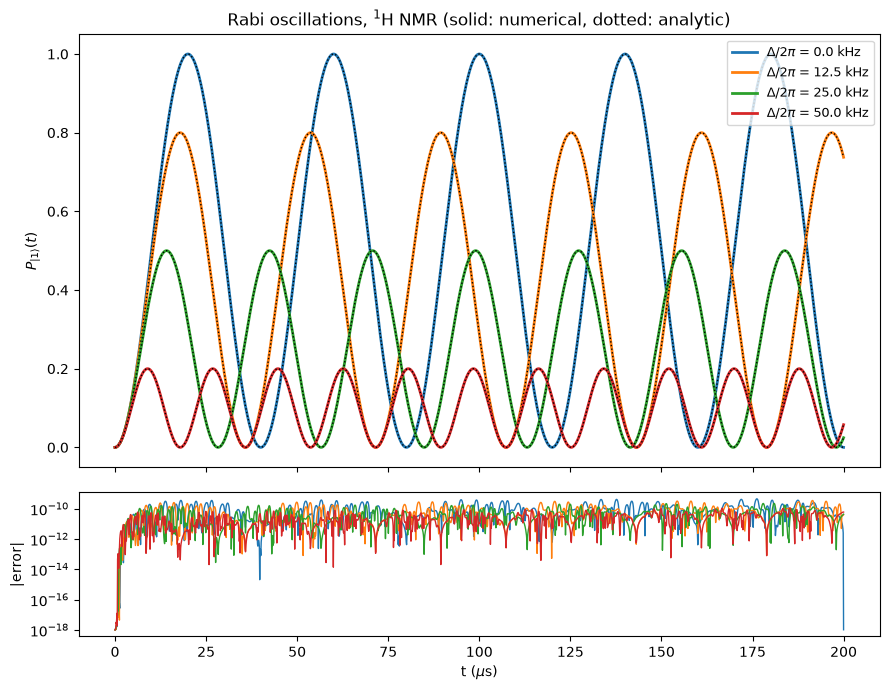

In [4]:
t = np.linspace(0, 200e-6, 2000)
detunings_hz = [0.0, 12.5e3, 25e3, 50e3]

fig, (ax_p, ax_e) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
for d_hz in detunings_hz:
    delta = 2 * np.pi * d_hz
    h = hamiltonian_rot(omega=OMEGA_R, delta=delta)
    psi = evolve_schrodinger(lambda _t: h, KET0, t)
    p_num = np.abs(psi[:, 1]) ** 2
    p_an = rabi_analytic(t, omega=OMEGA_R, delta=delta)
    ax_p.plot(t * 1e6, p_num, lw=2, label=rf"$\Delta/2\pi$ = {d_hz / 1e3:.1f} kHz")
    ax_p.plot(t * 1e6, p_an, "k:", lw=1)
    ax_e.semilogy(t * 1e6, np.abs(p_num - p_an) + 1e-18, lw=1)
    print(f"Delta/2pi = {d_hz / 1e3:5.1f} kHz | max P1 (theory) = {OMEGA_R**2 / (OMEGA_R**2 + delta**2):.3f}"
          f" | max P1 (numeric) = {p_num.max():.3f} | max |error| = {np.max(np.abs(p_num - p_an)):.2e}")

ax_p.set_ylabel(r"$P_{|1\rangle}(t)$")
ax_p.set_title("Rabi oscillations, $^1$H NMR (solid: numerical, dotted: analytic)")
ax_p.legend(loc="upper right", fontsize=9)
ax_e.set_xlabel(r"t ($\mu$s)")
ax_e.set_ylabel("|error|")
fig.tight_layout()
plt.show()

**Observations.** The numerical and analytic curves agree to about $10^{-10}$, which is the solver tolerance. Detuning has two effects: it lowers the maximum transfer as $\Omega^2/(\Omega^2+\Delta^2)$ and it increases the oscillation frequency to $\Omega_\text{eff} = \sqrt{\Omega^2+\Delta^2}$.

## 4. Bloch sphere trajectories

At resonance the effective field points along $x$, so the spin rotates through the poles. With detuning the rotation axis tilts to $(\Omega, 0, \Delta)/\Omega_\text{eff}$ and the trajectory is a smaller circle that never reaches $|1\rangle$.

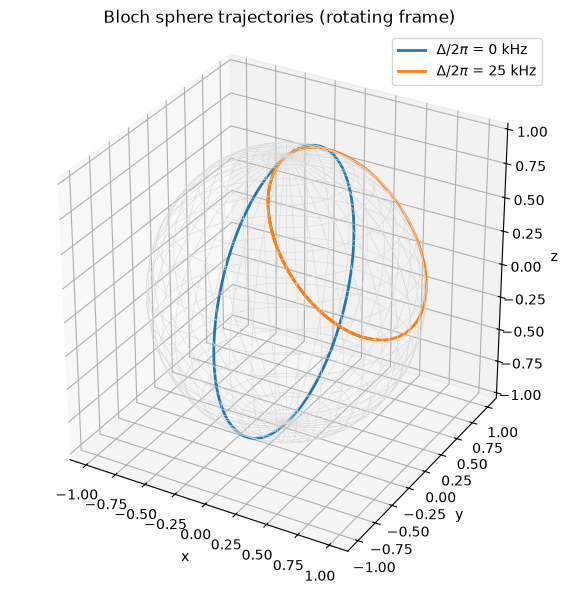

In [5]:
fig = plt.figure(figsize=(7, 7))
ax3 = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
ax3.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="0.85", lw=0.4)

t_short = np.linspace(0, 40e-6, 800)
for d_hz in (0.0, 25e3):
    h = hamiltonian_rot(omega=OMEGA_R, delta=2 * np.pi * d_hz)
    r = bloch_vector(evolve_schrodinger(lambda _t: h, KET0, t_short))
    ax3.plot(r[:, 0], r[:, 1], r[:, 2], lw=2, label=rf"$\Delta/2\pi$ = {d_hz / 1e3:.0f} kHz")

ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z")
ax3.set_box_aspect((1, 1, 1))
ax3.set_title("Bloch sphere trajectories (rotating frame)")
ax3.legend()
plt.show()

### Compuerta X en la esfera de Bloch

Un pulso de duración $\pi/\Omega$ y fase 0 rota el espín $\pi$ alrededor de $x$ y lleva $|0\rangle$ a $|1\rangle$.

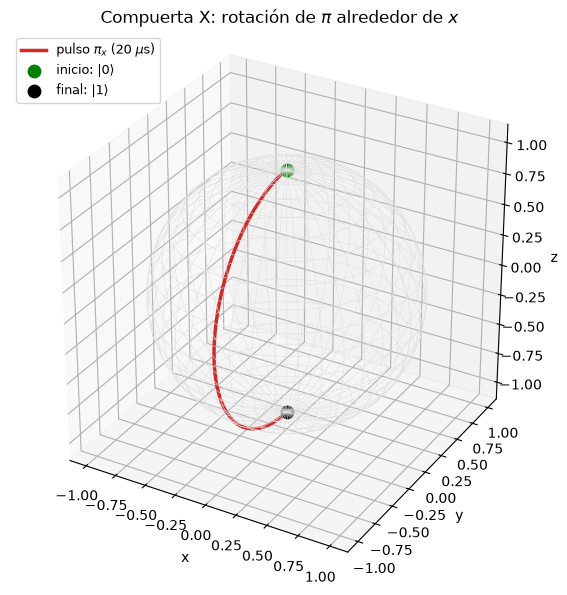

inicio: [0. 0. 1.]
final:  [ 0. -0. -1.]


In [6]:
import os
os.makedirs("figuras", exist_ok=True)

t_pi = np.pi / OMEGA_R
t_x = np.linspace(0, t_pi, 400)
h_x = hamiltonian_rot(omega=OMEGA_R, delta=0.0, phase=0.0)
r_x = bloch_vector(evolve_schrodinger(lambda _t: h_x, KET0, t_x))

fig = plt.figure(figsize=(7, 7))
ax3 = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
ax3.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="0.88", lw=0.4)
ax3.plot(r_x[:, 0], r_x[:, 1], r_x[:, 2], lw=2.5, color="tab:red", label=r"pulso $\pi_x$ (20 $\mu$s)")
ax3.scatter(*r_x[0], s=80, color="green", label=r"inicio: $|0\rangle$")
ax3.scatter(*r_x[-1], s=80, color="black", label=r"final: $|1\rangle$")
ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z")
ax3.set_box_aspect((1, 1, 1))
ax3.set_title(r"Compuerta X: rotación de $\pi$ alrededor de $x$")
ax3.legend(loc="upper left", fontsize=9)
fig.savefig("figuras/bloch_compuerta_X.png", dpi=200, bbox_inches="tight")
plt.show()

print("inicio:", np.round(r_x[0], 4))
print("final: ", np.round(r_x[-1], 4))


## 5. Validity of the rotating-wave approximation

In the lab frame a linearly polarized RF field $B_x = 2B_1\cos(\omega t)$ gives

$$H_\text{lab}(t) = \frac{\omega_0}{2}\sigma_z + \Omega\cos(\omega t)\,\sigma_x .$$

This field is the sum of a co-rotating and a counter-rotating component; the RWA drops the counter-rotating one. The real ratio $\omega_0/\Omega \approx 1000$ makes the lab-frame ODE very stiff, so we use scaled values $\omega_0/\Omega = 5$ and $50$ to see the trend.

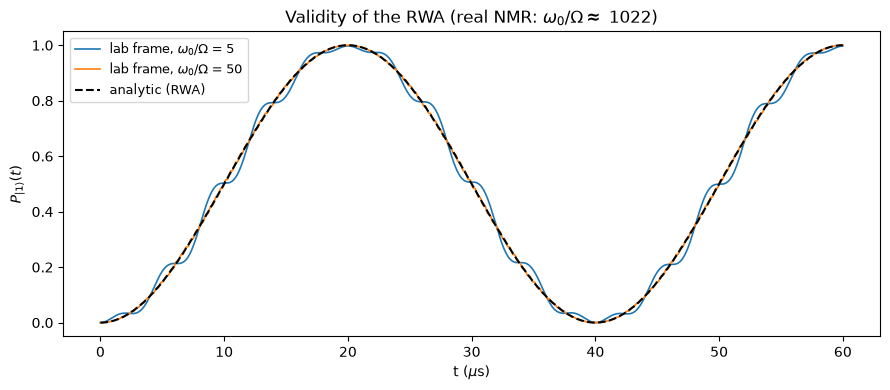

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
t_lab = np.linspace(0, 60e-6, 3000)
for ratio in (5, 50):
    w0 = ratio * OMEGA_R
    h_lab = lambda tt, w0=w0: 0.5 * w0 * SZ + OMEGA_R * np.cos(w0 * tt) * SX
    psi = evolve_schrodinger(h_lab, KET0, t_lab, max_step=2 * np.pi / w0 / 30)
    ax.plot(t_lab * 1e6, np.abs(psi[:, 1]) ** 2, lw=1.2, label=rf"lab frame, $\omega_0/\Omega$ = {ratio}")
ax.plot(t_lab * 1e6, rabi_analytic(t_lab, omega=OMEGA_R, delta=0.0), "k--", lw=1.5, label="analytic (RWA)")
ax.set_xlabel(r"t ($\mu$s)"); ax.set_ylabel(r"$P_{|1\rangle}(t)$")
ax.set_title(rf"Validity of the RWA (real NMR: $\omega_0/\Omega \approx$ {OMEGA_0 / OMEGA_R:.0f})")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Observations.** For $\omega_0/\Omega = 5$ there are fast wiggles at $2\omega_0$ from the counter-rotating term (Bloch-Siegert effect). For $\omega_0/\Omega = 50$ the lab-frame result already overlaps with the analytic curve, so in real NMR ($\approx 1000$) the RWA is excellent.

## 6. Decoherence: $T_1$ and $T_2$ with SpinQ Gemini Mini values

With relaxation, the magnetization obeys the Bloch equations in the rotating frame:

$$\dot{\mathbf M} = \boldsymbol\Omega_\text{eff}\times\mathbf M - \frac{M_x\hat x + M_y\hat y}{T_2} - \frac{(M_z - M_0)\hat z}{T_1}, \qquad \boldsymbol\Omega_\text{eff} = (\Omega, 0, \Delta),$$

and $P_{|1\rangle} = (1 - M_z)/2$. This is a linear system $\dot{\mathbf M} = A\mathbf M + \mathbf b$, so its exact solution is

$$\mathbf M(t) = \mathbf M_\text{ss} + e^{At}\left(\mathbf M(0) - \mathbf M_\text{ss}\right), \qquad \mathbf M_\text{ss} = -A^{-1}\mathbf b .$$

We evaluate it through the eigendecomposition of $A$, which allows long times (about $10^4$ Rabi periods) at no cost, and check it against direct ODE integration.

Coherence times from the SpinQ spec sheet:

| Device | $T_1$ | $T_2$ |
|---|---|---|
| Gemini Mini | ~3 s | ~150 ms |
| Gemini Mini Pro | ~5 s | ~200 ms |

For $\Omega \gg 1/T_{1,2}$ and $\Delta = 0$ the Rabi oscillation decays as $e^{-t/\tau_R}$ with $1/\tau_R = \tfrac{1}{2}\left(1/T_1 + 1/T_2\right)$.

In [8]:
SPINQ_DEVICES: dict[str, tuple[float, float]] = {
    "Gemini Mini": (3.0, 150e-3),       # (T1, T2) [s]
    "Gemini Mini Pro": (5.0, 200e-3),
}


def bloch_matrix(
    *, omega: float, delta: float, t1: float, t2: float, m0: float = 1.0
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    '''
    Matrix form dM/dt = A M + b of the rotating-frame Bloch equations.

    Args:
        omega: Rabi angular frequency [rad/s].
        delta: detuning [rad/s].
        t1:    longitudinal relaxation time [s].
        t2:    transverse relaxation time [s].
        m0:    equilibrium magnetization along z.

    Returns:
        Tuple (A, b) with the 3x3 matrix and the inhomogeneous term.

    Raises:
        ValueError if t2 > 2 * t1 (unphysical).
    '''
    if t2 > 2 * t1:
        raise ValueError("t2 must satisfy t2 <= 2 * t1")
    a = np.array([[-1 / t2, -delta, 0.0],
                  [delta, -1 / t2, -omega],
                  [0.0, omega, -1 / t1]])
    b = np.array([0.0, 0.0, m0 / t1])
    return a, b


def bloch_exact(
    t: NDArray[np.float64], *, omega: float, delta: float, t1: float, t2: float, m0: float = 1.0
) -> NDArray[np.float64]:
    '''
    Exact solution of the Bloch equations starting from thermal equilibrium (0, 0, m0).

    Args:
        t:     array of times [s].
        omega: Rabi angular frequency [rad/s].
        delta: detuning [rad/s].
        t1:    longitudinal relaxation time [s].
        t2:    transverse relaxation time [s].
        m0:    equilibrium magnetization along z.

    Returns:
        Array of shape (len(t), 3) with (Mx, My, Mz).
    '''
    a, b = bloch_matrix(omega=omega, delta=delta, t1=t1, t2=t2, m0=m0)
    m_ss = -np.linalg.solve(a, b)
    lam, vec = np.linalg.eig(a)
    coef = np.linalg.solve(vec, np.array([0.0, 0.0, m0]) - m_ss)
    return (m_ss[None, :] + (np.exp(np.outer(t, lam)) * coef) @ vec.T).real


def bloch_ode(
    t: NDArray[np.float64], *, omega: float, delta: float, t1: float, t2: float, m0: float = 1.0
) -> NDArray[np.float64]:
    '''
    Numerical integration of the Bloch equations, used to validate bloch_exact.

    Args:
        t:     array of output times [s].
        omega: Rabi angular frequency [rad/s].
        delta: detuning [rad/s].
        t1:    longitudinal relaxation time [s].
        t2:    transverse relaxation time [s].
        m0:    equilibrium magnetization along z.

    Returns:
        Array of shape (len(t), 3) with (Mx, My, Mz).
    '''
    a, b = bloch_matrix(omega=omega, delta=delta, t1=t1, t2=t2, m0=m0)
    sol = solve_ivp(lambda _t, m: a @ m + b, (t[0], t[-1]), [0.0, 0.0, m0], t_eval=t,
                    method="DOP853", rtol=1e-10, atol=1e-12)
    return sol.y.T


# Validation of the exact solution on a 2 ms window
t_chk = np.linspace(0, 2e-3, 4000)
t1_m, t2_m = SPINQ_DEVICES["Gemini Mini"]
err = np.max(np.abs(bloch_exact(t_chk, omega=OMEGA_R, delta=0.0, t1=t1_m, t2=t2_m)
                    - bloch_ode(t_chk, omega=OMEGA_R, delta=0.0, t1=t1_m, t2=t2_m)))
print(f"max |exact - ODE| over 2 ms: {err:.2e}\n")

t_pi = np.pi / OMEGA_R
for name, (t1, t2) in SPINQ_DEVICES.items():
    tau_r = 2 / (1 / t1 + 1 / t2)
    print(f"{name:16s} T1 = {t1:.0f} s, T2 = {t2 * 1e3:.0f} ms | tau_R = {tau_r * 1e3:.0f} ms"
          f" | pi pulses within T2 = {t2 / t_pi:,.0f}")

max |exact - ODE| over 2 ms: 2.83e-09

Gemini Mini      T1 = 3 s, T2 = 150 ms | tau_R = 286 ms | pi pulses within T2 = 7,500
Gemini Mini Pro  T1 = 5 s, T2 = 200 ms | tau_R = 385 ms | pi pulses within T2 = 10,000


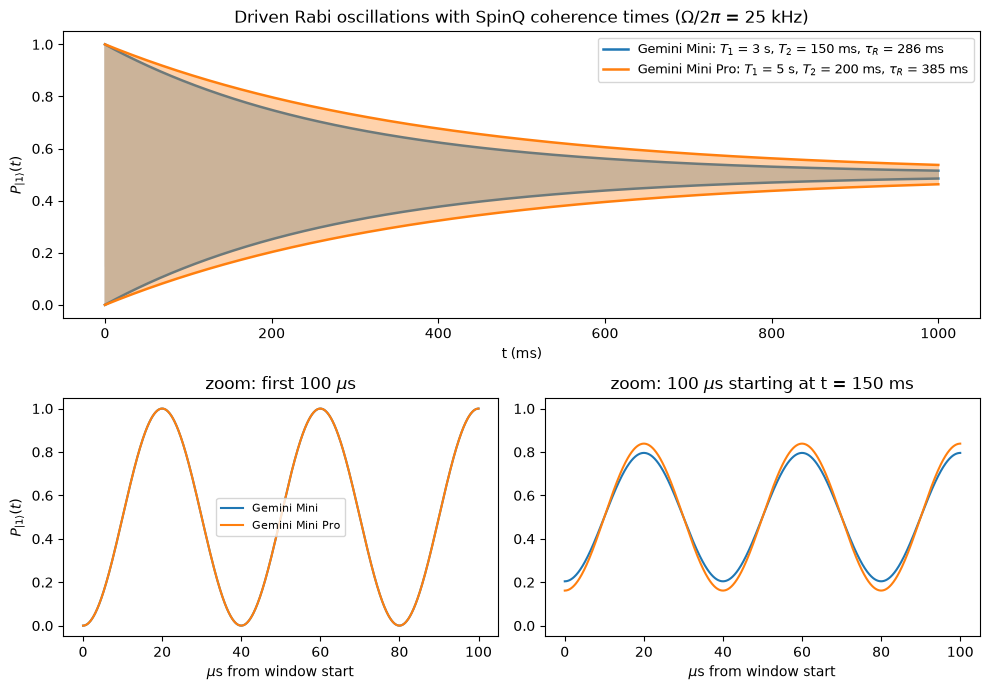

In [9]:
fig = plt.figure(figsize=(10, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])
ax_full = fig.add_subplot(gs[0, :])
ax_z0 = fig.add_subplot(gs[1, 0])
ax_z1 = fig.add_subplot(gs[1, 1], sharey=ax_z0)

t_full = np.linspace(0, 1.0, 400_001)               # 1 s, ~16 points per Rabi period
t_zoom0 = np.linspace(0, 100e-6, 1000)
t_zoom1 = np.linspace(150e-3, 150e-3 + 100e-6, 1000)
colors = {"Gemini Mini": "tab:blue", "Gemini Mini Pro": "tab:orange"}

for name, (t1, t2) in SPINQ_DEVICES.items():
    c = colors[name]
    p_full = (1 - bloch_exact(t_full, omega=OMEGA_R, delta=0.0, t1=t1, t2=t2)[:, 2]) / 2
    tau_r = 2 / (1 / t1 + 1 / t2)
    env = 0.5 * np.exp(-t_full / tau_r)
    ax_full.plot(t_full * 1e3, p_full, color=c, lw=0.3, alpha=0.35, rasterized=True)
    ax_full.plot(t_full * 1e3, 0.5 + env, color=c, lw=1.8,
                 label=rf"{name}: $T_1$ = {t1:.0f} s, $T_2$ = {t2 * 1e3:.0f} ms, $\tau_R$ = {tau_r * 1e3:.0f} ms")
    ax_full.plot(t_full * 1e3, 0.5 - env, color=c, lw=1.8)
    for ax, tz in ((ax_z0, t_zoom0), (ax_z1, t_zoom1)):
        pz = (1 - bloch_exact(tz, omega=OMEGA_R, delta=0.0, t1=t1, t2=t2)[:, 2]) / 2
        ax.plot((tz - tz[0]) * 1e6, pz, color=c, lw=1.5, label=name)

ax_full.set_xlabel("t (ms)"); ax_full.set_ylabel(r"$P_{|1\rangle}(t)$")
ax_full.set_title(r"Driven Rabi oscillations with SpinQ coherence times ($\Omega/2\pi$ = 25 kHz)")
ax_full.legend(fontsize=9, loc="upper right")
ax_z0.set_title(r"zoom: first 100 $\mu$s")
ax_z1.set_title(r"zoom: 100 $\mu$s starting at t = 150 ms")
for ax in (ax_z0, ax_z1):
    ax.set_xlabel(r"$\mu$s from window start")
ax_z0.set_ylabel(r"$P_{|1\rangle}(t)$")
ax_z0.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Observations.** With the SpinQ coherence times the oscillation is practically undamped on the time scale of a gate: a $\pi$ pulse lasts 20 $\mu$s, while the contrast decays with $\tau_R \approx 2T_2$ (about 290 ms for the Mini and 390 ms for the Mini Pro). After 150 ms the oscillation amplitude has dropped to roughly 60 to 70\% of its initial value and the populations tend to the mixed state $P = 0.5$. The ratio $T_2/t_\pi \sim 10^4$ is an upper bound on the number of coherent operations. The measured algorithm fidelities on the spec sheet (0.80 to 0.90 for Grover and Deutsch) are much lower than this bound suggests, because they are also limited by pulse calibration errors, RF inhomogeneity, the two-qubit J-coupling gates and readout, not only by $T_1$ and $T_2$.

## 7. Single-qubit gates as RF pulses

A pulse of duration $\tau$ and phase $\phi$ applies $U = e^{-iH\tau}$, a rotation by angle $\theta = \Omega\tau$ about an axis in the $xy$ plane.

- **X gate:** $180^\circ_x$ pulse ($\tau = \pi/\Omega$), $R_x(\pi) = -iX$.
- **Hadamard:** $90^\circ_y$ followed by $180^\circ_x$, $R_x(\pi)R_y(\pi/2) = -iH$.

Fidelity (insensitive to global phase): $F = |\mathrm{Tr}(V^\dagger U)|/2$.

X gate (180_x, 20.0 us)               F = 1.000000
Hadamard (90_y then 180_x, 30.0 us)  F = 1.000000
X gate, 1 kHz off resonance            F = 0.999200
X gate, 5 kHz off resonance            F = 0.980106


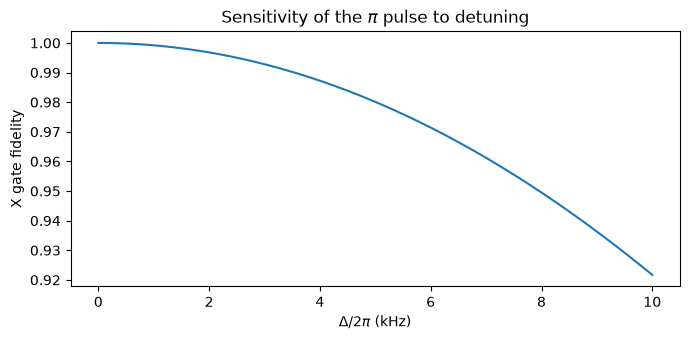

In [10]:
def gate_fidelity(u: NDArray[np.complex128], v: NDArray[np.complex128]) -> float:
    '''
    Phase-insensitive fidelity between two single-qubit unitaries.

    Args:
        u: implemented unitary.
        v: target unitary.

    Returns:
        F = |Tr(V^dagger U)| / 2.
    '''
    return float(abs(np.trace(v.conj().T @ u)) / 2)


t_pi = np.pi / OMEGA_R
u_x = expm(-1j * hamiltonian_rot(omega=OMEGA_R, delta=0.0, phase=0.0) * t_pi)
u_y90 = expm(-1j * hamiltonian_rot(omega=OMEGA_R, delta=0.0, phase=np.pi / 2) * t_pi / 2)
u_h = u_x @ u_y90
hadamard = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

print(f"X gate (180_x, {t_pi * 1e6:.1f} us)               F = {gate_fidelity(u_x, SX):.6f}")
print(f"Hadamard (90_y then 180_x, {1.5 * t_pi * 1e6:.1f} us)  F = {gate_fidelity(u_h, hadamard):.6f}")

d_scan = np.linspace(0, 10e3, 200)
f_scan = [gate_fidelity(expm(-1j * hamiltonian_rot(omega=OMEGA_R, delta=2 * np.pi * d) * t_pi), SX)
          for d in d_scan]
for d_hz in (1e3, 5e3):
    u_off = expm(-1j * hamiltonian_rot(omega=OMEGA_R, delta=2 * np.pi * d_hz) * t_pi)
    print(f"X gate, {d_hz / 1e3:.0f} kHz off resonance            F = {gate_fidelity(u_off, SX):.6f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(d_scan / 1e3, f_scan)
ax.set_xlabel(r"$\Delta/2\pi$ (kHz)"); ax.set_ylabel("X gate fidelity")
ax.set_title(r"Sensitivity of the $\pi$ pulse to detuning")
fig.tight_layout()
plt.show()

**Observations.** On resonance the pulses implement the gates exactly. An off-resonance error tilts the rotation axis and the fidelity drops quadratically with $\Delta/\Omega$, so calibrating the RF frequency to the Larmor frequency is essential.